# 02 · From forecasts to calibrated infection probability

Notebook 01 produced a biological label for every night. If the model saw the *observed* weather
of the target night it would just re-learn that rule, so instead each training row is what was
**knowable on the issue date**: the GFS forecast actually issued for the night *k* days ahead
(k = 1…7), plus recent weather up to 11:00 that morning. "Recent weather" is the GFS
lead-0 series rather than reanalysis, because that is what the live job has; reanalysis is
used only for the labels.

1. What the model sees: the same night forecast 7, 6, … 1 days ahead
2. How biased the raw forecast is
3. The feature table
4. GPU training — and when the GPU actually pays off
5. Out-of-sample skill (leave-one-season-out CV) vs. baselines
6. What drives the predictions
7. The model across a full season, and one forecast from start to finish

Inputs come from `src/features.py` and `src/train.py` (run those first).

In [1]:
import sys, pathlib, time, json
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import xgboost as xgb
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss

from src import config, plot_style as ps
from src.label_infection import load_hourly, hourly_flags, infection_night
from src.features import forecast_long_from_leads, feature_columns

X = pd.read_csv(config.FEATURES_CSV, parse_dates=["issue", "night"])
oof = pd.read_csv(config.OOF_PREDICTIONS_CSV, parse_dates=["issue", "night"])
meta = json.loads(config.MODEL_META_PATH.read_text())
print(f"{len(X)} rows, {len(feature_columns(X))} features, {len(oof)} out-of-fold predictions, "
      f"model trained on {meta['device']}")

7144 rows, 52 features, 7088 out-of-fold predictions, model trained on cuda


## 1. What the model sees: one night, seven forecasts

Open-Meteo archives every past GFS run, so for any night we can recover what the forecast looked
like 7 days ahead, 6 days ahead, and so on. Below is a night where the raw forecast only "found"
the infection conditions in the last couple of days. Darker lines are closer to the night.

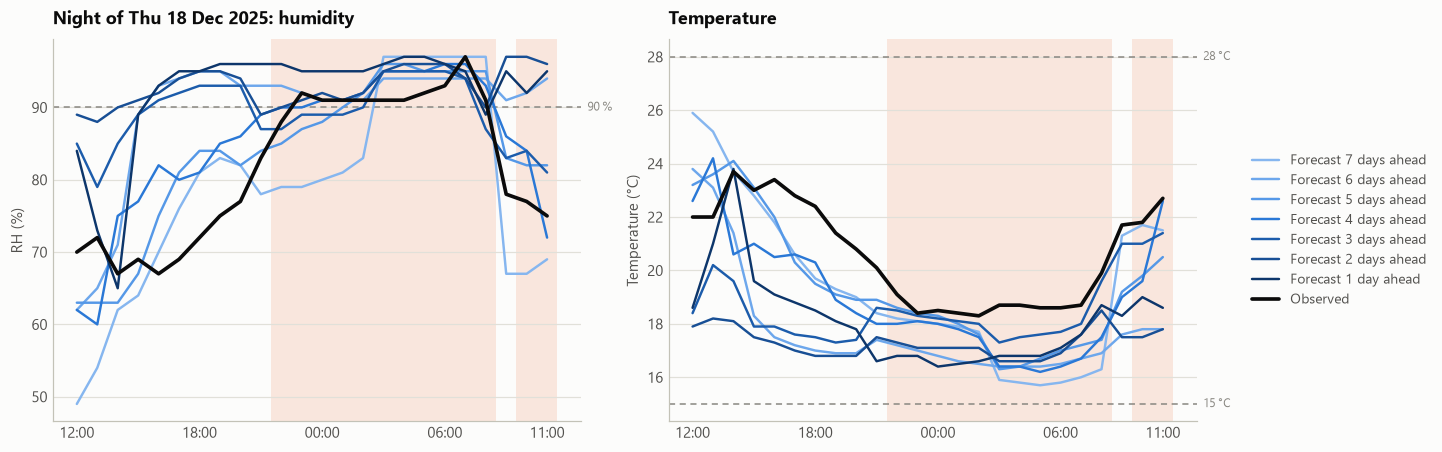

lead,1,2,3,4,5,6,7
raw-rule score by lead,0.76,0.73,0.49,0.51,0.35,0.68,0.13


In [2]:
hourly = load_hourly()
fc_long = forecast_long_from_leads(pd.read_csv(config.RAW_PREVIOUS_RUNS_CSV))
fc_long["night"] = pd.to_datetime(infection_night(fc_long.time_local))
fc_long["lead"] = (fc_long.night - fc_long.issue).dt.days + 1

score = X.pivot_table(index="night", columns="lead", values="fc_infection_score")
y_night = X.drop_duplicates("night").set_index("night").y_event
cand = score[(score[1] > 0.7) & (score[7] < 0.2)].join(y_night).query("y_event == 1")
night = cand.index[-1]

start = pd.Timestamp(night).tz_localize(config.LOCAL_TZ) + pd.Timedelta(hours=12)
obs = hourly[(hourly.time_local >= start) & (hourly.time_local < start + pd.Timedelta(hours=24))].reset_index(drop=True)
hrs = np.arange(24)
ramp = {7: 3, 6: 4, 5: 5, 4: 7, 3: 9, 2: 10, 1: 12}       # light = far ahead, dark = close (ordinal ramp)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for ax, var, ylab in [(axes[0], "relative_humidity_2m", "RH (%)"), (axes[1], "temperature_2m", "Temperature (°C)")]:
    ps.shade_runs(ax, hrs, hourly_flags(obs).fav)
    for k in range(7, 0, -1):
        f = fc_long[(fc_long.night == night) & (fc_long.lead == k)].sort_values("time_utc")
        ax.plot(hrs[:len(f)], f[var].to_numpy(), color=ps.BLUE_RAMP[ramp[k]], lw=1.6,
                label=f"Forecast {k} day{'s' if k > 1 else ''} ahead")
    ax.plot(hrs, obs[var], color=ps.INK, lw=2.4, label="Observed")
    ax.set_ylabel(ylab)
    ax.set_xticks([0, 6, 12, 18, 23], ["12:00", "18:00", "00:00", "06:00", "11:00"])
ps.threshold(axes[0], y=90, label="90 %")
ps.threshold(axes[1], y=15, label="15 °C"); ps.threshold(axes[1], y=28, label="28 °C")
axes[0].set_title(f"Night of {pd.Timestamp(night):%a %d %b %Y}: humidity")
axes[1].set_title("Temperature")
axes[1].legend(loc="center left", bbox_to_anchor=(1.08, 0.5))
plt.show()
score.loc[night].rename("raw-rule score by lead").round(2).to_frame().T

## 2. How biased is the raw forecast?

Applying the biological rule directly to the GFS forecast flags infection more often than it
actually happens, and the over-forecast grows with lead time. Correcting this is the model's job.

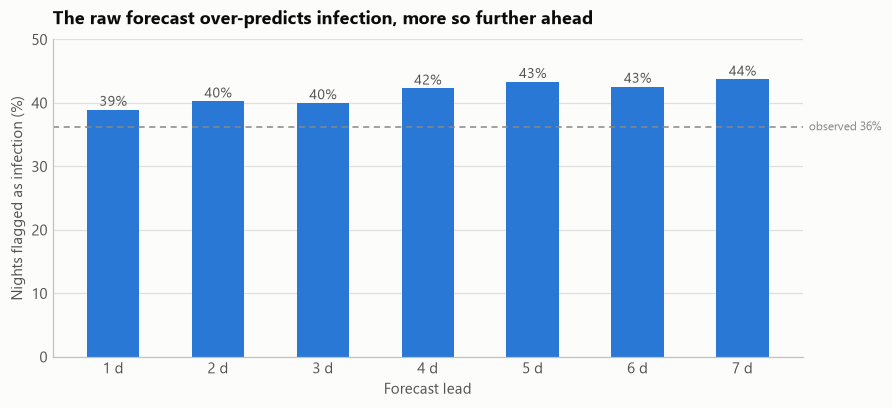

,rule_rate,observed,accuracy
lead,,,
1,38.9,36.4,84.7
2,40.3,36.3,84.1
3,40.0,36.2,83.6
4,42.3,36.1,83.5
5,43.3,36.2,83.0
6,42.6,36.0,80.4
7,43.7,36.1,80.7


In [3]:
L = X.dropna(subset=["y_event"])
by_lead = L.groupby("lead").agg(rule_rate=("fc_infection_event", "mean"), observed=("y_event", "mean"),
                                accuracy=("fc_infection_event", lambda s: (s == L.loc[s.index, "y_event"]).mean()))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(by_lead.index, by_lead.rule_rate * 100, color=ps.BLUE, width=0.5, label="Raw forecast + rule")
ps.threshold(ax, y=by_lead.observed.mean() * 100, label=f"observed {by_lead.observed.mean():.0%}")
for k, v in by_lead.rule_rate.items():
    ax.text(k, v * 100 + 0.6, f"{v:.0%}", ha="center", fontsize=9, color=ps.INK_2)
ax.set_ylim(0, 50); ax.set_xticks(by_lead.index, [f"{k} d" for k in by_lead.index])
ax.set_xlabel("Forecast lead"); ax.set_ylabel("Nights flagged as infection (%)")
ax.set_title("The raw forecast over-predicts infection, more so further ahead")
plt.show()
(by_lead * 100).round(1)

## 3. The feature table

52 features per (issue date, lead) row, in three families:

- `fc_*` — the infection rule and summaries computed on the forecast for the target night
  (wet hours, longest favourable run, rain, RH, dew-point depression, wind, cloud) and its neighbours
- `obs_*` — antecedent conditions at the cutoff, from the GFS lead-0 series: rolling 24 h – 14 d wetness, rain,
  temperature variance, consecutive humid hours, recent infection nights
- `lead`, `doy_sin`, `doy_cos` — forecast horizon and season

In [4]:
feats = feature_columns(X)
fam = pd.Series({f: "forecast (fc_)" if f.startswith("fc_") else "observed (obs_)" if f.startswith("obs_") else "calendar / lead" for f in feats})
print(fam.value_counts().to_string())
X[["issue", "lead", "night", "fc_fav_hours", "fc_max_run_hours", "fc_infection_score",
   "obs_rh_mean_168h", "obs_events_last7", "y_event"]].sample(6, random_state=1).sort_values(["issue", "lead"])

observed (obs_)    28
forecast (fc_)     21
calendar / lead     3


,issue,lead,night,fc_fav_hours,fc_max_run_hours,fc_infection_score,obs_rh_mean_168h,obs_events_last7,y_event
2098,2024-11-13,6,2024-11-18,11,8.0,0.4287,81.6250,5.0,0.0
2328,2024-12-16,5,2024-12-20,24,24.0,0.9028,86.0238,7.0,1.0
2902,2025-03-08,5,2025-03-12,14,14.0,0.7032,69.9286,3.0,1.0
3738,2025-07-06,1,2025-07-06,0,0.0,0.0000,61.6012,0.0,0.0
5877,2026-05-09,1,2026-05-09,1,0.0,0.0000,73.3393,1.0,0.0
6954,2026-10-09,7,2026-10-15,24,24.0,0.8526,82.7024,6.0,1.0


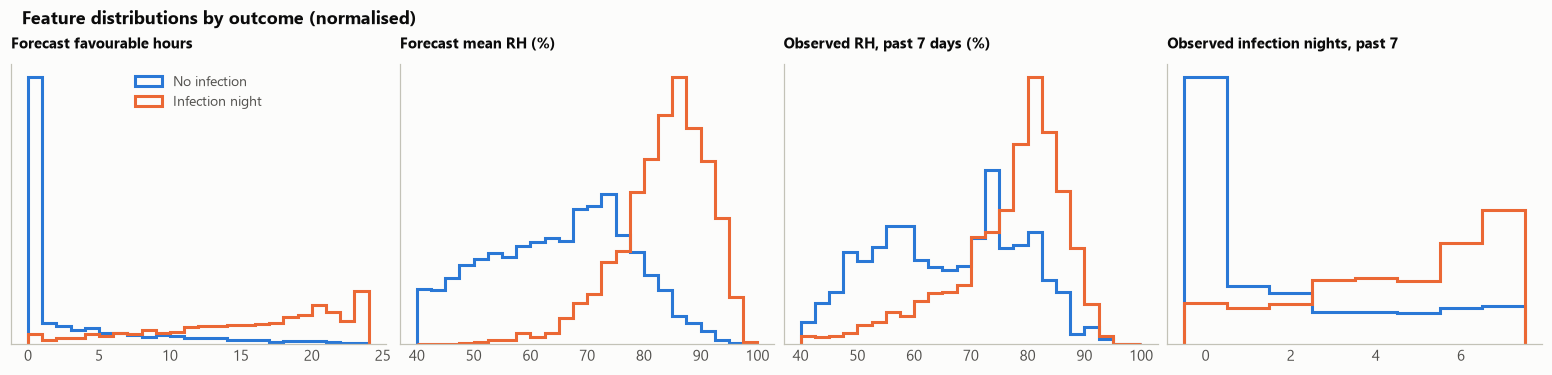

In [5]:
show = [("fc_fav_hours", "Forecast favourable hours", np.arange(0, 25, 1)),
        ("fc_rh_mean", "Forecast mean RH (%)", np.arange(40, 101, 2.5)),
        ("obs_rh_mean_168h", "Observed RH, past 7 days (%)", np.arange(40, 101, 2.5)),
        ("obs_events_last7", "Observed infection nights, past 7", np.arange(-0.5, 8, 1))]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for ax, (col, title, bins) in zip(axes, show):
    for yv, color, lab in [(0, ps.BLUE, "No infection"), (1, ps.SERIES[1], "Infection night")]:
        ax.hist(L.loc[L.y_event == yv, col].dropna(), bins=bins, density=True, histtype="step", lw=2, color=color, label=lab)
    ax.set_title(title, fontsize=10); ax.set_yticks([])
axes[0].legend(loc="upper center")
fig.suptitle("Feature distributions by outcome (normalised)", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.show()

## 4. GPU training — and when the GPU actually pays off

The model is trained with `XGBClassifier(device="cuda", tree_method="hist")` on an RTX 3060. With
~7k rows the dataset is small, so here is a timing of a fixed 300-tree model on CPU vs GPU,
then on the same table replicated to simulate a multi-site (many municipalities) setup.

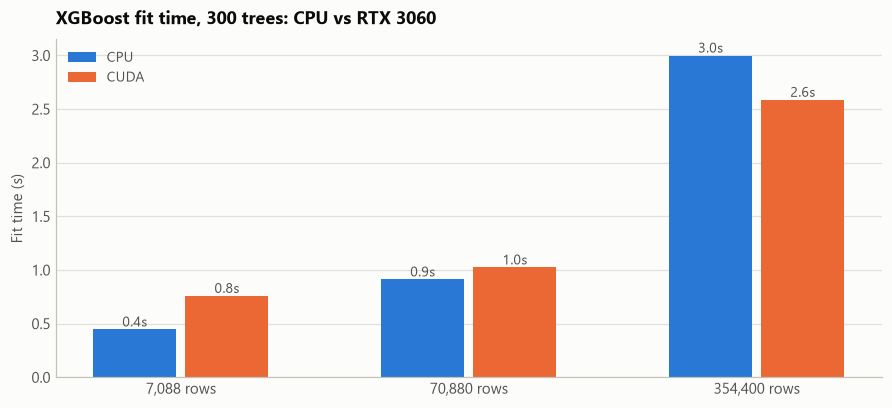

device,CPU,CUDA,speedup
rows,,,
7088,0.45,0.76,0.59
70880,0.91,1.02,0.89
354400,3.00,2.59,1.16


In [6]:
Xm, ym = L[feats], L.y_event.astype(int)
params = dict(n_estimators=300, max_depth=6, learning_rate=0.05, tree_method="hist")
xgb.XGBClassifier(**params, device="cuda").fit(Xm.iloc[:500], ym.iloc[:500])     # warm up CUDA context

rows = []
for mult in (1, 10, 50):
    Xb = pd.concat([Xm] * mult, ignore_index=True); yb = pd.concat([ym] * mult, ignore_index=True)
    for dev in ("cpu", "cuda"):
        t0 = time.perf_counter(); xgb.XGBClassifier(**params, device=dev).fit(Xb, yb)
        rows.append({"rows": len(Xb), "device": dev.upper(), "seconds": time.perf_counter() - t0})
timing = pd.DataFrame(rows)

piv = timing.pivot(index="rows", columns="device", values="seconds")
fig, ax = plt.subplots(figsize=(8, 3.6))
xpos = np.arange(len(piv)); w = 0.32
for i, (dev, color) in enumerate([("CPU", ps.BLUE), ("CUDA", ps.SERIES[1])]):
    bars = ax.bar(xpos + (i - 0.5) * w, piv[dev], width=w * 0.9, color=color, label=dev)
    for b, v in zip(bars, piv[dev]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}s", ha="center", va="bottom", fontsize=9, color=ps.INK_2)
ax.set_xticks(xpos, [f"{r:,} rows" for r in piv.index])
ax.set_ylabel("Fit time (s)"); ax.set_title("XGBoost fit time, 300 trees: CPU vs RTX 3060")
ax.legend(loc="upper left")
plt.show()
piv.assign(speedup=lambda d: d.CPU / d.CUDA).round(2)

At this scale the GPU gives little or no speed-up: XGBoost's CPU `hist` algorithm handles even
~350k rows in a few seconds, and on the real 7k-row table the CUDA launch overhead makes the GPU
*slower*. GPU training pays off with millions of rows, deeper trees or large hyperparameter
searches — e.g. a gridded forecaster covering every coffee municipality in Minas Gerais.

## 5. Out-of-sample skill

Predictions below are **out-of-fold**: each coffee season (Jul–Jun) was predicted by a model that
never saw it, with an 8-day purge around the test block (`python -m src.train`).

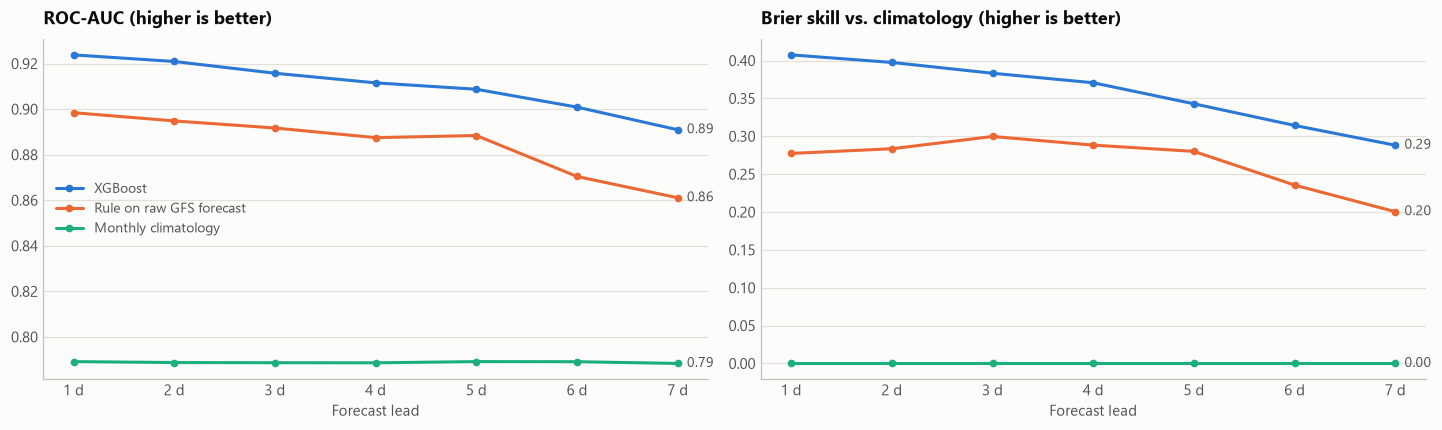

lead,1,2,3,4,5,6,7
model,,,,,,,
Monthly climatology,0.789,0.789,0.789,0.789,0.789,0.789,0.788
Rule on raw GFS forecast,0.898,0.895,0.892,0.887,0.888,0.870,0.861
XGBoost,0.924,0.921,0.916,0.912,0.909,0.901,0.891


In [7]:
models = {"XGBoost": ("p_model", ps.BLUE), "Rule on raw GFS forecast": ("p_fc_score", ps.SERIES[1]),
          "Monthly climatology": ("p_climatology", ps.SERIES[2])}
rows = []
for lead, g in oof.groupby("lead"):
    clim_b = brier_score_loss(g.y_event, g.p_climatology)
    for name, (col, _) in models.items():
        rows.append({"lead": lead, "model": name, "auc": roc_auc_score(g.y_event, g[col]),
                     "bss": 1 - brier_score_loss(g.y_event, g[col].clip(0, 1)) / clim_b})
skill = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, metric, title in [(axes[0], "auc", "ROC-AUC (higher is better)"),
                          (axes[1], "bss", "Brier skill vs. climatology (higher is better)")]:
    for name, (_, color) in models.items():
        s = skill[skill.model == name]
        ax.plot(s.lead, s[metric], color=color, marker="o", ms=4, label=name)
        ax.annotate(f"{s[metric].iloc[-1]:.2f}", (7, s[metric].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color=ps.INK_2)
    ax.set_xticks(range(1, 8), [f"{k} d" for k in range(1, 8)]); ax.set_xlabel("Forecast lead")
    ax.set_title(title)
axes[0].legend(loc="center left")
plt.show()
skill.pivot(index="model", columns="lead", values="auc").round(3)

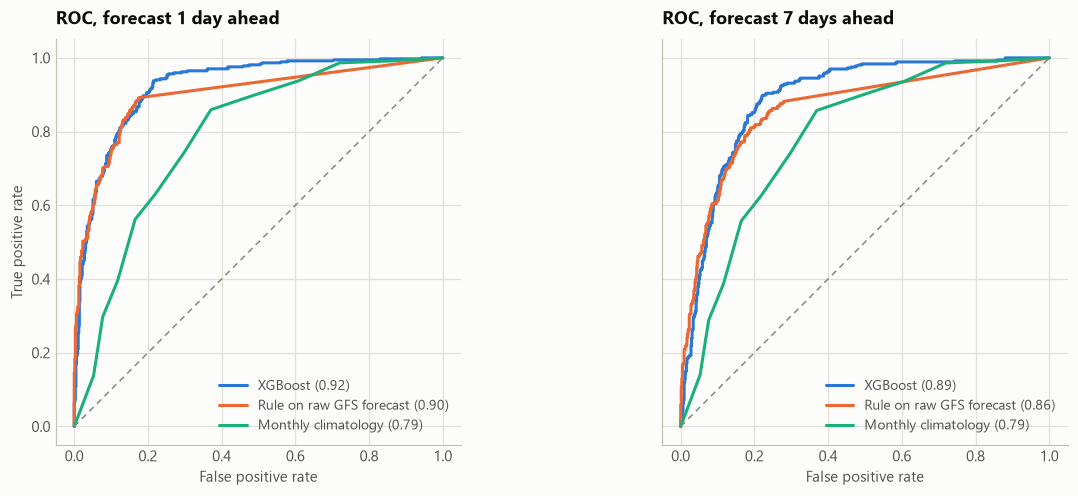

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, lead in zip(axes, (1, 7)):
    g = oof[oof.lead == lead]
    for name, (col, color) in models.items():
        fpr, tpr, _ = roc_curve(g.y_event, g[col])
        ax.plot(fpr, tpr, color=color, label=f"{name} ({roc_auc_score(g.y_event, g[col]):.2f})")
    ax.plot([0, 1], [0, 1], color=ps.MUTED, lw=1, ls=(0, (4, 3)))
    ax.set_title(f"ROC, forecast {lead} day{'s' if lead > 1 else ''} ahead")
    ax.set_xlabel("False positive rate"); ax.set_aspect("equal"); ax.grid(axis="x", visible=True)
    ax.legend(loc="lower right")
axes[0].set_ylabel("True positive rate")
plt.show()

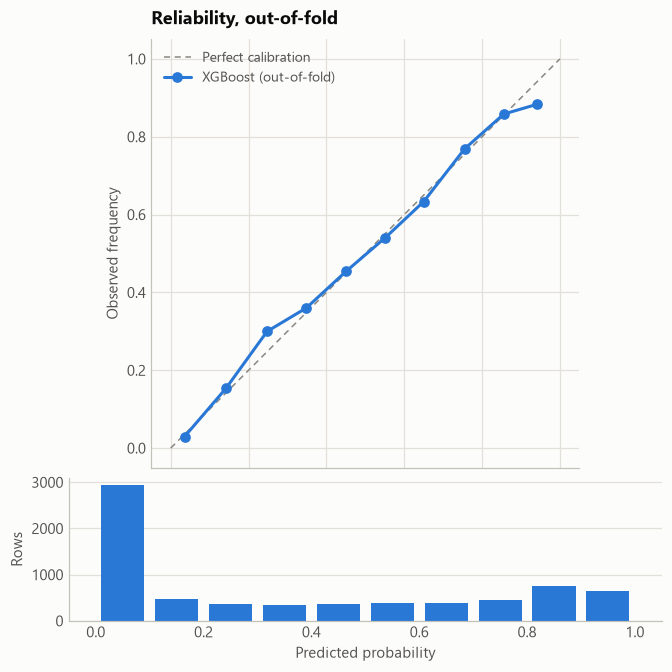

,pred,obs,n
bin,,,
"(-0.001, 0.1]",0.036,0.030,2942
"(0.1, 0.2]",0.142,0.153,470
"(0.2, 0.3]",0.248,0.300,357
"(0.3, 0.4]",0.348,0.360,336
"(0.4, 0.5]",0.451,0.455,374
"(0.5, 0.6]",0.551,0.540,383
"(0.6, 0.7]",0.650,0.634,382
"(0.7, 0.8]",0.755,0.769,446
"(0.8, 0.9]",0.856,0.858,748


In [9]:
bins = np.linspace(0, 1, 11)
oof["bin"] = pd.cut(oof.p_model, bins, include_lowest=True)
rel = oof.groupby("bin", observed=True).agg(pred=("p_model", "mean"), obs=("y_event", "mean"), n=("y_event", "size"))

fig, (ax, axn) = plt.subplots(2, 1, figsize=(6, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot([0, 1], [0, 1], color=ps.MUTED, lw=1, ls=(0, (4, 3)), label="Perfect calibration")
ax.plot(rel.pred, rel.obs, color=ps.BLUE, marker="o", ms=6, label="XGBoost (out-of-fold)")
ax.set_ylabel("Observed frequency"); ax.set_title("Reliability, out-of-fold")
ax.set_aspect("equal"); ax.grid(axis="x", visible=True); ax.legend(loc="upper left")
axn.bar(bins[:-1] + 0.05, rel.n.reindex(rel.index).values, width=0.08, color=ps.BLUE)
axn.set_ylabel("Rows"); axn.set_xlabel("Predicted probability")
plt.show()
rel.round(3)

## 6. What drives the predictions

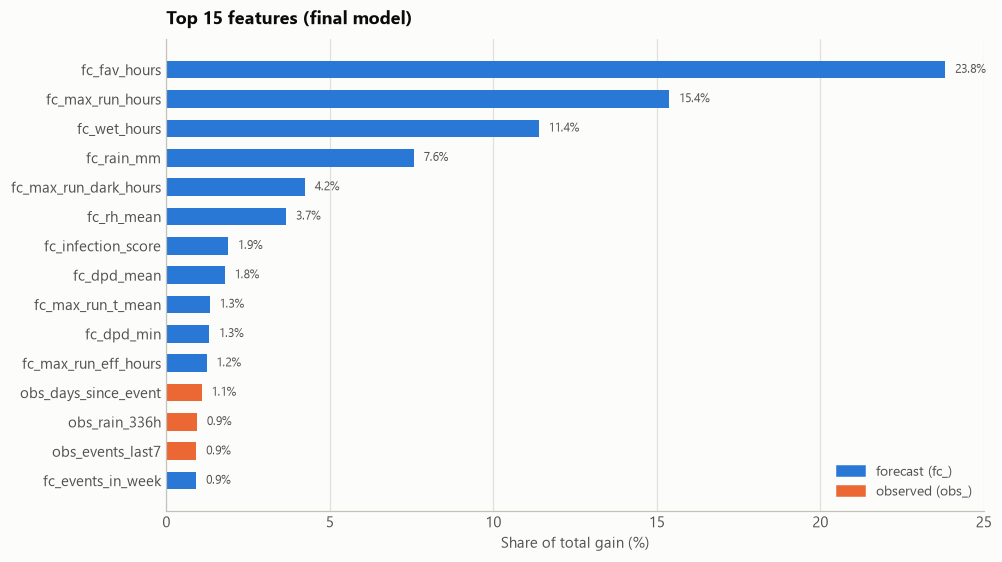

forecast (fc_)     80.1%
observed (obs_)    17.6%
calendar / lead     2.3%
Name: gain share by family, dtype: str

In [10]:
booster = xgb.Booster(); booster.load_model(config.MODEL_PATH)
gain = pd.Series(booster.get_score(importance_type="gain")).sort_values(ascending=False)
top = (gain / gain.sum()).head(15)[::-1]
fam_color = {"forecast (fc_)": ps.BLUE, "observed (obs_)": ps.SERIES[1], "calendar / lead": ps.SERIES[2]}

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top.values * 100, color=[fam_color[fam[f]] for f in top.index], height=0.6)
for y, v in enumerate(top.values):
    ax.text(v * 100 + 0.3, y, f"{v:.1%}", va="center", fontsize=8, color=ps.INK_2)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Share of total gain (%)"); ax.set_title("Top 15 features (final model)")
ax.legend(handles=[Patch(color=c, label=k) for k, c in fam_color.items() if k in set(fam[top.index])], loc="lower right")
plt.show()
(gain / gain.sum()).groupby(fam).sum().sort_values(ascending=False).map("{:.1%}".format).rename("gain share by family")

The model leans mostly on the forecast for the target night — it is essentially learning *how to
read* the GFS forecast for this site (how many forecast "wet" hours really mean leaf wetness).
Observed antecedent conditions (recent humidity, recent infection nights) supply most of the rest.

## 7. The model across a full season

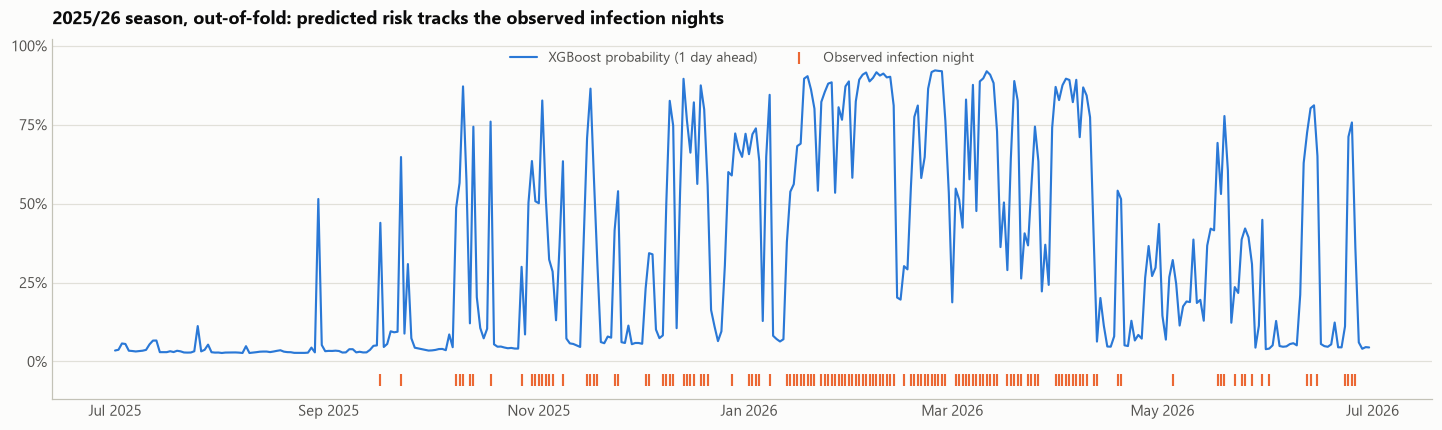

In [11]:
season = oof[(oof.lead == 1) & (oof.season == 2025)].sort_values("night")
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(season.night, season.p_model, color=ps.BLUE, lw=1.4, label="XGBoost probability (1 day ahead)")
ev = season[season.y_event == 1]
ax.scatter(ev.night, np.full(len(ev), -0.06), marker="|", s=60, color=ps.SERIES[1], lw=1.4, label="Observed infection night")
ax.set_ylim(-0.12, 1.02); ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("2025/26 season, out-of-fold: predicted risk tracks the observed infection nights")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
plt.show()

### One forecast from start to finish

Pick an issue date whose week had a mix of infection and dry nights, and compare the 7 nightly
probabilities with what actually happened.

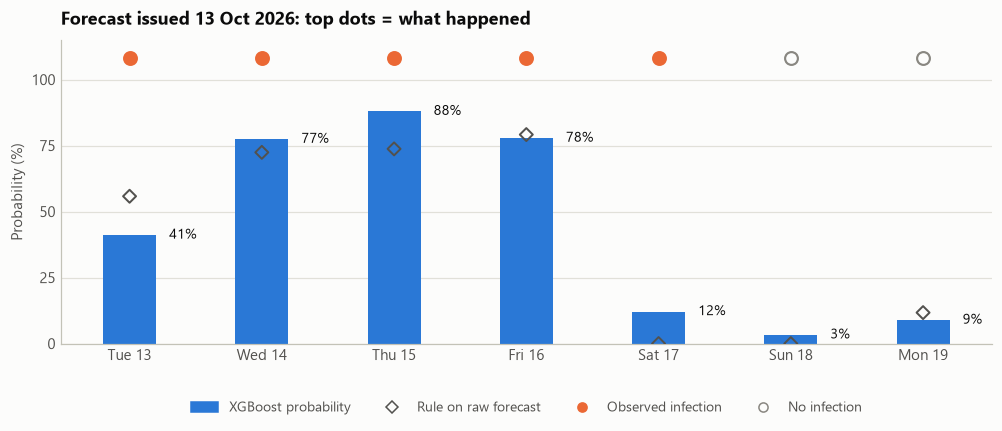

,night,lead,y_event,p_model,p_fc_score,p_climatology
6976,2026-10-13,1,1,0.411,0.558,0.394
6977,2026-10-14,2,1,0.774,0.724,0.394
6978,2026-10-15,3,1,0.879,0.737,0.394
6979,2026-10-16,4,1,0.778,0.792,0.394
6980,2026-10-17,5,1,0.121,0.000,0.394
6981,2026-10-18,6,0,0.033,0.000,0.394
6982,2026-10-19,7,0,0.089,0.117,0.394


In [12]:
g = oof[oof.season >= 2025].groupby("issue")
mixed = g.filter(lambda d: len(d) == 7 and 2 <= d.y_event.sum() <= 5)
issue = mixed.groupby("issue").p_model.agg(lambda p: p.max() - p.min()).idxmax()
week = oof[oof.issue == issue].sort_values("lead")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(week.lead, week.p_model * 100, color=ps.BLUE, width=0.4, label="XGBoost probability")
ax.scatter(week.lead, week.p_fc_score * 100, marker="D", s=36, facecolor="none", edgecolor=ps.INK_2,
           lw=1.3, label="Rule on raw forecast (score)", zorder=3)
for k, p, y in zip(week.lead, week.p_model, week.y_event):
    ax.text(k + 0.3, p * 100, f"{p:.0%}", ha="left", va="center", fontsize=9, color=ps.INK)
    ax.scatter([k], [108], s=70, marker="o", color=ps.SERIES[1] if y else ps.SURFACE,
               edgecolor=ps.SERIES[1] if y else ps.MUTED, lw=1.4, zorder=3)
ax.set_ylim(0, 115); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xticks(week.lead, [f"{n:%a %d}" for n in week.night])
ax.set_ylabel("Probability (%)")
ax.set_title(f"Forecast issued {pd.Timestamp(issue):%d %b %Y}: top dots = what happened")
ax.legend(handles=[Patch(color=ps.BLUE, label="XGBoost probability"),
                   Line2D([], [], marker="D", ls="", mfc="none", mec=ps.INK_2, label="Rule on raw forecast"),
                   Line2D([], [], marker="o", ls="", color=ps.SERIES[1], label="Observed infection"),
                   Line2D([], [], marker="o", ls="", mfc=ps.SURFACE, mec=ps.MUTED, label="No infection")],
          loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)
plt.show()
week[["night", "lead", "y_event", "p_model", "p_fc_score", "p_climatology"]].round({"p_model": 3, "p_fc_score": 3, "p_climatology": 3})

## Takeaways

- Training on **archived forecasts**, not observed weather, means the model learns to correct
  the GFS forecast rather than re-learn the labeling rule.
- XGBoost beats the raw-forecast rule and climatology at every lead (AUC ≈ 0.92 at 1 day → 0.89 at
  7 days) and its probabilities are well calibrated, slightly overconfident above 90 %.
- The GPU is not necessary at single-site scale (measured above); it becomes worthwhile for
  much larger multi-site tables or heavy hyperparameter searches.